# 03 — Fine-tuned DistilBERT (WELFake sweep) and the LIAR 3-way head (MSE2)

**Fake News & Misinformation Detector** · MSE2 criteria *Model Training* and *Model Tuning* (master doc §12.2–12.3, MSE2 doc §3–4).

This notebook **does not train**: it loads what `make train-distilbert` / `make train-liar` saved on the RTX 2050.

**Status (2026-10-26):** the WELFake sweep was **stopped on user decision after 3 of 6 configs** (lr {2e-5, 3e-5, 5e-5} at
max_len 256). The three max_len 512 runs and the full-train retrain did not run and are deferred to ESE. Sweep runs keep no weights, so
there is **no DistilBERT WELFake checkpoint and no DistilBERT test number**. The served classifier stays TF-IDF and MSE2 objective O1
is not checked. The LIAR 3-way head ran completely.

Code: `src/models/distilbert.py`, `src/models/liar_head.py`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C
from src.models import distilbert as D
from src.models import liar_head as L
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
recs = D.sweep_records()
print("hardware:", recs[0]["hardware"])
print("WELFake DistilBERT checkpoint present:", (D.FINAL_DIR / "config.json").exists())

hardware: {'gpu': 'NVIDIA GeForce RTX 2050', 'gpu_mem_gib': 3.68, 'cpu': 'x86_64', 'python': '3.11.11', 'torch': '2.14.1+cu130', 'transformers': '4.57.6'}
WELFake DistilBERT checkpoint present: False


## 1. Sweep on a 20k stratified subset (selection metric: val macro-F1)

Fixed settings: AdamW, linear schedule, warmup ratio 0.1, weight decay 0.01, fp16, seed 42, input `title [SEP] text` head-truncated, batch 16 at
max_len 256. Validation = the full WELFake val split (6,080 rows).

In [2]:
rows = []
for r in recs:
    c = r["config"]
    rows.append({"lr": f"{c['lr']:.0e}", "max_len": c["max_len"], "batch×accum": f"{c['per_device_batch']}×{c['grad_accum']}",
                 "best_epoch": r["best_epoch"], **{f"val_F1_ep{e['epoch']}": e["val_macro_f1"] for e in r["per_epoch"]},
                 **{f"val_loss_ep{e['epoch']}": e["val_loss"] for e in r["per_epoch"]},
                 "best_val_macro_F1": r["best_val_macro_f1"], "minutes": r["minutes"], "peak_GPU_GiB": r["peak_gpu_mem_gib"]})
pd.DataFrame(rows).sort_values("best_val_macro_F1", ascending=False).reset_index(drop=True)

,lr,max_len,batch×accum,best_epoch,val_F1_ep1,val_F1_ep2,val_F1_ep3,val_loss_ep1,val_loss_ep2,val_loss_ep3,best_val_macro_F1,minutes,peak_GPU_GiB
0,5e-05,256,16×1,3,0.9792,0.9870,0.9871,0.0833,0.0572,0.0671,0.9871,15.2,1.69
1,2e-05,256,16×1,3,0.9792,0.9807,0.9869,0.0803,0.0792,0.0651,0.9869,14.8,1.68
2,3e-05,256,16×1,3,0.9826,0.9854,0.9863,0.0635,0.0556,0.0611,0.9863,14.3,1.68


| run | lr | max_len | batch × accum | best epoch / 3 | warmup | seed | val macro-F1 (best ep.) | val acc | per-epoch val macro-F1 | minutes | peak GPU GiB | hardware |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| sweep 20k (20000) | 2e-05 | 256 | 16 × 1 | 3 | 0.1 | 42 | **0.9869** | 0.9872 | 0.9792 → 0.9807 → 0.9869 | 14.8 | 1.68 | NVIDIA GeForce RTX 2050 |
| sweep 20k (20000) | 3e-05 | 256 | 16 × 1 | 3 | 0.1 | 42 | **0.9863** | 0.9865 | 0.9826 → 0.9854 → 0.9863 | 14.3 | 1.68 | NVIDIA GeForce RTX 2050 |
| **best completed** sweep 20k (20000) | 5e-05 | 256 | 16 × 1 | 3 | 0.1 | 42 | **0.9871** | 0.9873 | 0.9792 → 0.9870 → 0.9871 | 15.2 | 1.69 | NVIDIA GeForce RTX 2050 |
| sweep 20k | 2e-05 | 512 | 8 × 2 | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |
| sweep 20k | 3e-05 | 512 | 8 × 2 | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |
| sweep 20k | 5e-05 | 512 | 8 × 2 | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |
| full-train retrain of the winner (48,639) | — | — | — | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |

**Best completed run:** lr = 5e-05, max_len = 256 (val macro-F1 0.9871 at epoch 3). Only 3 of 6 configs ran, so this is the best of the completed runs, not a sweep winner; the sweep runs save no weights, so **no DistilBERT checkpoint exists** and no DistilBERT test number exists (`data/models/distilbert-welfake-v1/` was not created; the served classifier stays TF-IDF). MSE2 objective O1 (DistilBERT macro-F1 ≥ 0.95 on WELFake test) is therefore not checked.

**lr = 5e-5:** at max_len 256 it fits the 20k subset fastest (train loss 0.0077 at epoch 3 vs 0.0153 / 0.0105 for 2e-5 / 3e-5) and its val loss rises from epoch 2 (0.0572) to epoch 3 (0.0671), i.e. it starts to overfit, while val macro-F1 stays flat (0.9870 -> 0.9871); it ties lr 2e-5 (0.9869) within 0.0002 — no lr is clearly better at 256.



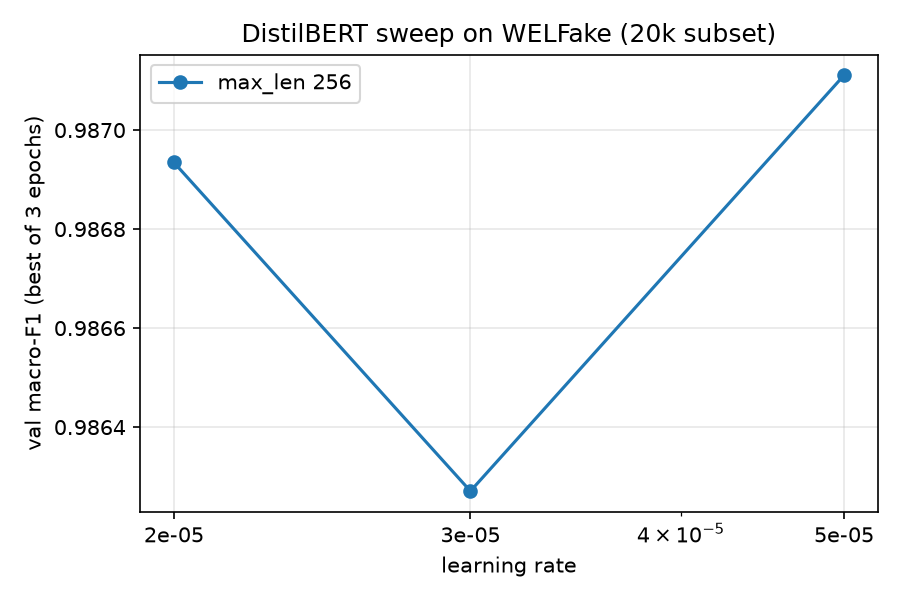

In [3]:
display(Markdown(D.SWEEP_MD.read_text().split("\n\n", 2)[2]))
display(Image(str(C.FIGURES_DIR / "sweep_distilbert_lr.png")))

## 2. Training curve of the best completed sweep run

There was no full-train retrain, so `docs/figures/train_distilbert.png` shows the best **20k-subset** run: train loss logged every 50 steps
plus the per-epoch mean, val loss, and val macro-F1 per epoch with the best epoch marked.

,train_loss,val_loss,val_macro_f1,val_accuracy,val_roc_auc
epoch,,,,,
1,0.1736,0.0833,0.9792,0.9796,0.9979
2,0.0385,0.0572,0.9870,0.9872,0.9991
3,0.0077,0.0671,0.9871,0.9873,0.9993


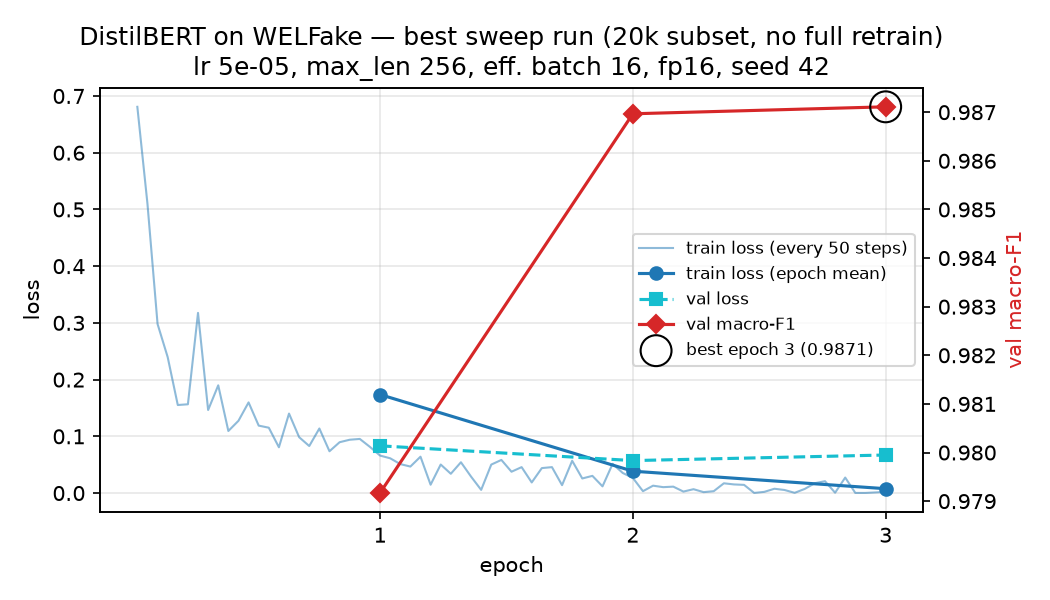

In [4]:
best = max(recs, key=lambda r: r["best_val_macro_f1"])
display(pd.DataFrame(best["per_epoch"]).set_index("epoch"))
display(Image(str(C.FIGURES_DIR / "train_distilbert.png")))

## 5. LIAR 3-way head (TRUE / MIXED / FALSE)

Statement text only (speaker / party are label proxies), class-weighted cross-entropy, max_len 64, LIAR official splits.
Wang (2017) reports 6-way accuracy only, so the winning config is also trained 6-way for a like-for-like comparison.

,lr,epochs,best_epoch,best_val_macro_F1,minutes
0,2e-05,3,2,0.4695,2.6
1,2e-05,5,3,0.4616,3.9
2,3e-05,3,2,0.4773,2.3
3,3e-05,5,2,0.4554,4.2


### Test (official LIAR test, 1,283 statements)

| model | label space | test accuracy | test macro-F1 |
|---|---|---|---|
| majority class (train) | 3-way | 0.3749 | — |
| **DistilBERT 3-way head (ours)** | 3-way | **0.4669** | **0.4667** |
| DistilBERT 6-way twin, predictions collapsed 6→3 | 3-way | 0.4669 | 0.4637 |
| majority class (train) | 6-way | 0.2081 | — |
| DistilBERT 6-way twin (same config, ours) | 6-way | 0.2689 | 0.2686 |
| Wang (2017) majority | 6-way | 0.208 | n/r |
| Wang (2017) text-only CNN | 6-way | 0.270 | n/r |
| Wang (2017) hybrid CNN (text + all metadata) | 6-way | 0.274 | n/r |

Wang (2017) reports only 6-way accuracy (Table 2), so the 6-way twin is the like-for-like comparison; the 3-way head is what fusion consumes. 3-way confusion (rows = true TRUE/MIXED/FALSE, cols = predicted): `[[190, 170, 100], [99, 233, 149], [54, 112, 176]]`.



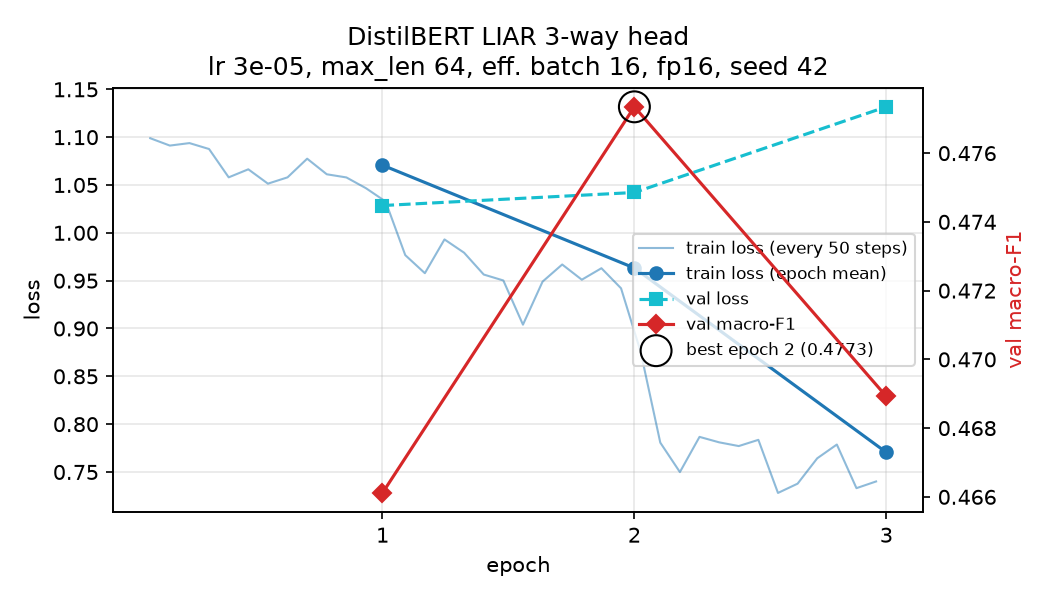

In [5]:
liar = json.loads(L.LOG.read_text())
display(pd.DataFrame([{"lr": f"{r['config']['lr']:.0e}", "epochs": r["config"]["epochs"], "best_epoch": r["best_epoch"],
                       "best_val_macro_F1": r["best_val_macro_f1"], "minutes": r["minutes"]} for r in liar["sweep"]]))
display(Markdown(L.MD.read_text().split("## Test")[1].join(["### Test", ""])))
display(Image(str(C.FIGURES_DIR / "train_liar.png")))

### Reload the LIAR checkpoint with `AutoModelForSequenceClassification`

The head shades claims TRUE / MIXED / FALSE. It is a confidence signal for fusion, never the verdict.

In [6]:
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer
tok = AutoTokenizer.from_pretrained(L.FINAL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(L.FINAL_DIR).eval()
claims = ["Says the unemployment rate fell to its lowest level in 50 years.",
          "Says vaccines contain microchips that track people.",
          "The federal budget deficit doubled under the current administration."]
with torch.no_grad():
    probs = torch.softmax(model(**tok(claims, padding=True, truncation=True, max_length=L.MAX_LEN, return_tensors="pt")).logits, -1)
pd.DataFrame(probs.numpy().round(3), columns=[model.config.id2label[i] for i in range(3)], index=claims)

,TRUE,MIXED,FALSE
Says the unemployment rate fell to its lowest level in 50 years.,0.329,0.454,0.217
Says vaccines contain microchips that track people.,0.050,0.260,0.690
The federal budget deficit doubled under the current administration.,0.615,0.195,0.190


## Summary

* The completed sweep runs and the LIAR head can be reproduced with `make train-distilbert` / `make train-liar` (seed 42; the logs in
  `docs/results/train_logs/` record the full config, hardware and wall-clock). `--sweep` skips runs whose log already exists, so re-running
  continues with the max_len 512 configs (deferred to ESE).
* Tables: `docs/results/distilbert_sweep.md`, `docs/results/liar_head.md`; figures: `docs/figures/train_distilbert.png`,
  `docs/figures/sweep_distilbert_lr.png`, `docs/figures/train_liar.png`.